# Types of Machine Learning: Four Ways to Ask One Question

## For Clinicians and Health-System Leaders

Most introductions to machine learning present a list: supervised, unsupervised,
semi-supervised, reinforcement. The list is accurate and almost useless, because it sounds
like a menu of algorithms you choose between.

It is not a menu of algorithms. **It is a list of questions.**

To show this, we will hold one thing fixed for the whole notebook: a single ward of
simulated patients, summarized into a single table. The data never changes. Only the
question changes. And the question is what decides which family of method applies.

| Section | The question | The family |
|---|---|---|
| 1 | *Which of these patients will deteriorate?* — and we know the answer for all of them | Supervised |
| 2 | *Are there natural groups here?* — we hide the answers entirely | Unsupervised |
| 3 | *Only 20 charts were reviewed. Can the other 950 patients still help?* | Semi-supervised |
| 4 | *What does a normal stay look like, and who departs from it?* | Self-supervised |

By the end you should be able to hear a project description and name the family it belongs
to, before anyone mentions an algorithm.

---

> ### The data in this notebook is simulated
>
> Every patient here is generated by `synthetic_vitals_generator.py` from published
> physiological ranges. No real or identifiable patient data is used anywhere in this
> course. Vital signs are clipped to plausible limits, and the direction of effect is
> clinically correct: deterioration raises heart rate, respiratory rate and temperature,
> and lowers blood pressure and oxygen saturation.
>
> These are teaching examples. Nothing here is a validated clinical tool, and nothing here
> should inform the care of a real patient.

## The shared cohort

We simulate a 1200-bed ward over 24 hours. A bedside monitor samples five channels every
five minutes: heart rate, mean arterial pressure, oxygen saturation, respiratory rate and
temperature.

Each patient follows one of four clinical archetypes:

| Archetype | What happens over the stay | Deteriorates? |
|---|---|---|
| **Stable** | Vitals hold near the patient's own baseline | No |
| **Post-operative recovery** | Starts perturbed after surgery, then settles | No |
| **Sepsis deterioration** | A slow early drift becomes a sharp decline | Yes |
| **Cardiac event** | A long quiet period, then an abrupt crisis | Yes |

Note the second row. Post-operative patients are **abnormal but not deteriorating**. They
will matter enormously in Section 4.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

sys.path.append("../..")
from synthetic_vitals_generator import VitalsGenerator, CHANNELS, ARCHETYPES

RANDOM_SEED = 42
plt.rcParams["figure.figsize"] = (11, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

# Simulated bedside monitoring: 1200 patients, 24 hours, sampled every 5 minutes.
generator = VitalsGenerator(seed=RANDOM_SEED)
raw = generator.generate_cohort(n_patients=1200, hours=24)

print(f"monitor readings : {len(raw):,}")
print(f"patients         : {raw['patient_id'].nunique():,}")
print(f"channels         : {', '.join(CHANNELS)}")
raw.head(3)

monitor readings : 345,600
patients         : 1,200
channels         : heart_rate, map_mmhg, spo2, resp_rate, temp_c


,patient_id,minutes_since_admission,heart_rate,map_mmhg,spo2,resp_rate,temp_c,timestamp,archetype,acuity,age,sex,deteriorating
0,P0000,0,84.488834,73.692918,95.437385,15.969714,36.509062,2026-01-01 00:00:00,sepsis_deterioration,3,47,F,0
1,P0000,5,86.486996,70.231752,94.913362,14.283111,36.496009,2026-01-01 00:05:00,sepsis_deterioration,3,47,F,0
2,P0000,10,87.720826,71.924111,94.690208,13.013438,36.412162,2026-01-01 00:10:00,sepsis_deterioration,3,47,F,0


### What a stay looks like

Before summarizing anything, look at the raw signal. One patient per archetype, heart rate
only. The vertical dashed line marks where the clinical event begins.

This matters for what follows: **the event starts between 35% and 70% of the way through
the stay.** Everything before it is the window a ward team would actually have to act on.

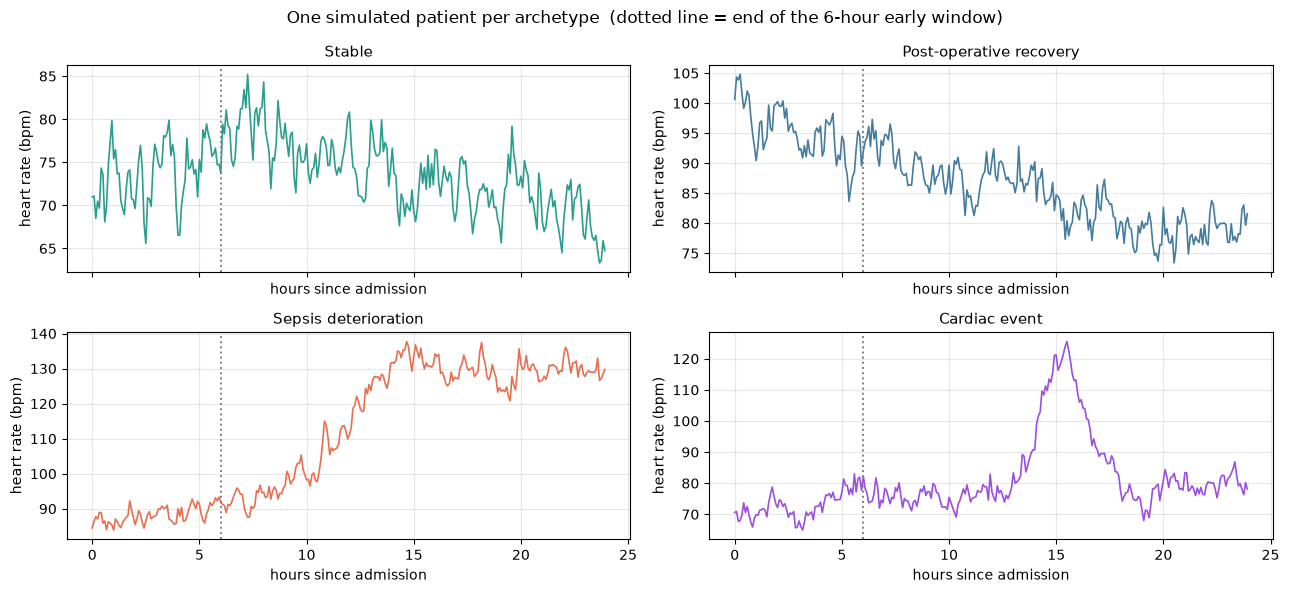

In [2]:
fig, axes = plt.subplots(2, 2, figsize=(13, 6), sharex=True)
colours = {"stable": "#2a9d8f", "post_op_recovery": "#457b9d",
           "sepsis_deterioration": "#e76f51", "cardiac_event": "#9d4edd"}

for ax, (name, meta) in zip(axes.ravel(), ARCHETYPES.items()):
    pid = raw.loc[raw["archetype"] == name, "patient_id"].iloc[0]
    stay = raw[raw["patient_id"] == pid]
    hours = stay["minutes_since_admission"] / 60.0
    ax.plot(hours, stay["heart_rate"], color=colours[name], lw=1.2)
    ax.axvline(6, color="grey", ls=":", lw=1.4)
    ax.set_title(meta["label"], fontsize=11)
    ax.set_ylabel("heart rate (bpm)")
    ax.set_xlabel("hours since admission")

fig.suptitle("One simulated patient per archetype  (dotted line = end of the 6-hour early window)",
             fontsize=12)
fig.tight_layout()
plt.show()

### Summarizing a stay into features

A model cannot consume a raw monitor trace directly. We reduce each patient's stay to a
small set of numbers — this step is **feature engineering**, and in a real project it
absorbs more clinical judgement than the modelling does.

For each of the five channels we take three summaries over the **first six hours only**:

- **mean** — where the patient sat
- **sd** — how much they fluctuated
- **slope** — which way they were trending, per hour

Five channels x three summaries = 15 features per patient.

**Why only the first six hours?** Because the clinical event always begins later than that.
If we summarized the whole stay, the deterioration would already be in the features and
every method below would score near-perfectly — which would teach nothing except that a
model can see what has already happened. Restricting to the early window makes this a
genuine prediction problem, and keeps the difficulty honest.

We then down-sample the deteriorating patients so they make up about 20% of the ward. A
balanced sample would be convenient and clinically false: most patients on most wards do
not deteriorate.

In [3]:
EARLY_WINDOW_HOURS = 6

def summarise_stay(stay: pd.DataFrame) -> pd.Series:
    """Reduce one patient's early monitoring window to 15 features."""
    early = stay[stay["minutes_since_admission"] < EARLY_WINDOW_HOURS * 60]
    hours = early["minutes_since_admission"].to_numpy() / 60.0

    features = {}
    for channel in CHANNELS:
        values = early[channel].to_numpy()
        features[f"{channel}_mean"] = values.mean()
        features[f"{channel}_sd"] = values.std()
        features[f"{channel}_slope"] = np.polyfit(hours, values, 1)[0]

    features["archetype"] = stay["archetype"].iloc[0]
    features["deteriorated"] = int(stay["deteriorating"].max())
    return pd.Series(features)


patients = raw.groupby("patient_id").apply(summarise_stay, include_groups=False)

# Down-sample the deteriorating group to a realistic ward prevalence (~20%).
well = patients[patients["deteriorated"] == 0]
unwell = patients[patients["deteriorated"] == 1]
patients = pd.concat([
    well,
    unwell.sample(int(len(well) * 0.25), random_state=RANDOM_SEED),
]).sample(frac=1, random_state=1)

FEATURES = [c for c in patients.columns if c not in ("archetype", "deteriorated")]

print(f"patients            : {len(patients)}")
print(f"features per patient: {len(FEATURES)}")
print(f"deterioration rate  : {patients['deteriorated'].mean():.1%}")
print()
print(patients.groupby("archetype").size().to_string())

patients            : 976
features per patient: 15
deterioration rate  : 20.0%

archetype
cardiac_event            81
post_op_recovery        285
sepsis_deterioration    114
stable                  496


This table — 976 rows, 15 feature columns, one label column — is now the **only** data used
for the rest of the notebook. Every section below reads from it. Nothing else is generated.

Keep that in mind as the four questions change. The patients do not change.

In [4]:
from sklearn.preprocessing import StandardScaler

X = StandardScaler().fit_transform(patients[FEATURES].to_numpy(float))
y = patients["deteriorated"].to_numpy()
archetypes = patients["archetype"].to_numpy()

print(f"feature matrix X : {X.shape}   (patients x features)")
print(f"label vector  y  : {y.shape}   ({y.sum()} deteriorated, {len(y) - y.sum()} did not)")

feature matrix X : (976, 15)   (patients x features)
label vector  y  : (976,)   (195 deteriorated, 781 did not)


---

# Question 1 — Supervised learning

> *"We reviewed all 976 charts. Which patients went on to deteriorate?"*

This is the question almost everyone means when they say "machine learning". We possess the
answer for every patient in the training set, and we want a model that reproduces it on
patients it has not seen.

The word **supervised** refers to the labels, not to a human watching the model. A label is
a recorded outcome: someone, at some point, read a chart and wrote down what happened. That
labelling effort is the expensive part, and it is the constraint Section 3 is about.

We hold out 30% of the ward as a test set. The model never sees those patients during
training, which is the only way to find out whether it learned anything transferable.

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, confusion_matrix, classification_report

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=RANDOM_SEED
)

model = LogisticRegression(max_iter=1000).fit(X_train, y_train)

probabilities = model.predict_proba(X_test)[:, 1]
predictions = model.predict(X_test)

print(f"training patients : {len(X_train)}")
print(f"held-out patients : {len(X_test)}")
print()
print(f"AUC on held-out patients: {roc_auc_score(y_test, probabilities):.3f}")
print()
print(classification_report(y_test, predictions,
                           target_names=["did not deteriorate", "deteriorated"]))

training patients : 683
held-out patients : 293

AUC on held-out patients: 0.869

                     precision    recall  f1-score   support

did not deteriorate       0.88      0.96      0.92       234
       deteriorated       0.76      0.47      0.58        59

           accuracy                           0.86       293
          macro avg       0.82      0.72      0.75       293
       weighted avg       0.85      0.86      0.85       293



An AUC in the mid-0.8s from six hours of monitoring is a plausible early-warning result —
good enough to be useful, far from good enough to act on unsupervised.

Look past the AUC at the recall for the deteriorating group. That is the number a clinician
cares about: of the patients who went on to deteriorate, what share did the model flag?
Missing them is a different kind of failure from a false alarm, and an overall accuracy
figure hides the distinction entirely. The precision/recall trade-off has its own notebook
in this course.

### What the model learned

Because logistic regression is linear, the coefficients are directly readable — one per
feature, with a sign.

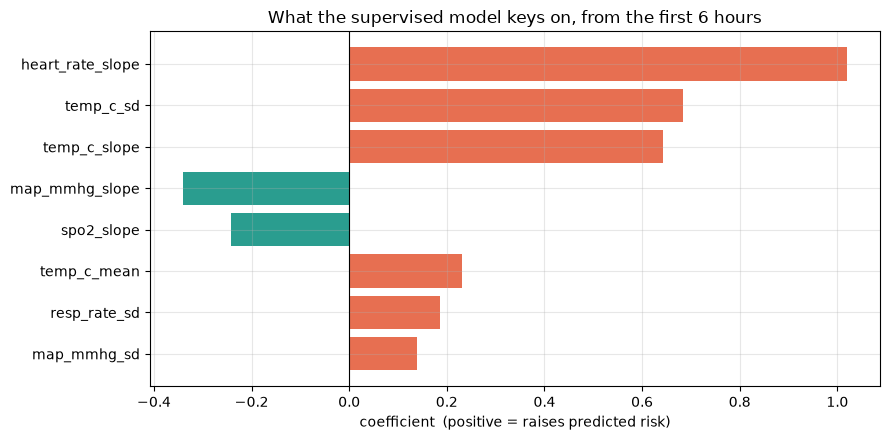

         feature  coefficient  strength
heart_rate_slope     1.019380  1.019380
       temp_c_sd     0.683399  0.683399
    temp_c_slope     0.641851  0.641851
  map_mmhg_slope    -0.340611  0.340611
      spo2_slope    -0.241499  0.241499
     temp_c_mean     0.231096  0.231096
    resp_rate_sd     0.185624  0.185624
     map_mmhg_sd     0.139561  0.139561


In [6]:
importance = (
    pd.DataFrame({"feature": FEATURES, "coefficient": model.coef_[0]})
    .assign(strength=lambda d: d["coefficient"].abs())
    .sort_values("strength", ascending=False)
)

top = importance.head(8).iloc[::-1]
colours_bar = ["#e76f51" if c > 0 else "#2a9d8f" for c in top["coefficient"]]

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(top["feature"], top["coefficient"], color=colours_bar)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("coefficient  (positive = raises predicted risk)")
ax.set_title("What the supervised model keys on, from the first 6 hours")
fig.tight_layout()
plt.show()

print(importance.head(8).to_string(index=False))

The directions should be clinically recognisable. A **rising heart rate** dominates, by some
margin. **Temperature** contributes twice — both its trend and its variability — which is the
early thermal instability of sepsis. **Falling mean arterial pressure** and **falling oxygen
saturation** carry negative coefficients, meaning a downward trend in either raises predicted
risk. That is the physiology of early deterioration, recovered from the data rather than
programmed in.

Note what is *absent*: respiratory rate trend contributes almost nothing this early, despite
being one of the strongest signs of established deterioration and a component of every
track-and-trigger score in use. In the first six hours it has not yet moved. A feature can be
clinically vital and still be useless at the moment you need to decide — which is an argument
about *when* you measure, not about which algorithm you chose.

This is worth pausing on, because it is the whole premise of Session 1. Nobody wrote a rule
saying *"if heart rate is climbing and pressure is falling, raise the risk."* The model
derived it from examples. That is the difference between programming and learning.

A caution, though: a readable coefficient is not a causal claim. The model has found what
*correlates* with deterioration in this simulated ward. It has not discovered why anyone
became unwell, and it would be wrong to present it as having done so.

---

# Question 2 — Unsupervised learning

> *"Forget the outcomes. Are there natural groups of patients in here at all?"*

Now we delete the labels. The `y` vector is set aside and the algorithm sees only the 15
feature columns. It is not told that deterioration exists, how many kinds of patient there
are, or what any group should look like.

The question has changed from *predict this known thing* to **is there structure here?**

This matters clinically because it is how you investigate a population you do not yet have
a vocabulary for. You cannot label what you have not named.

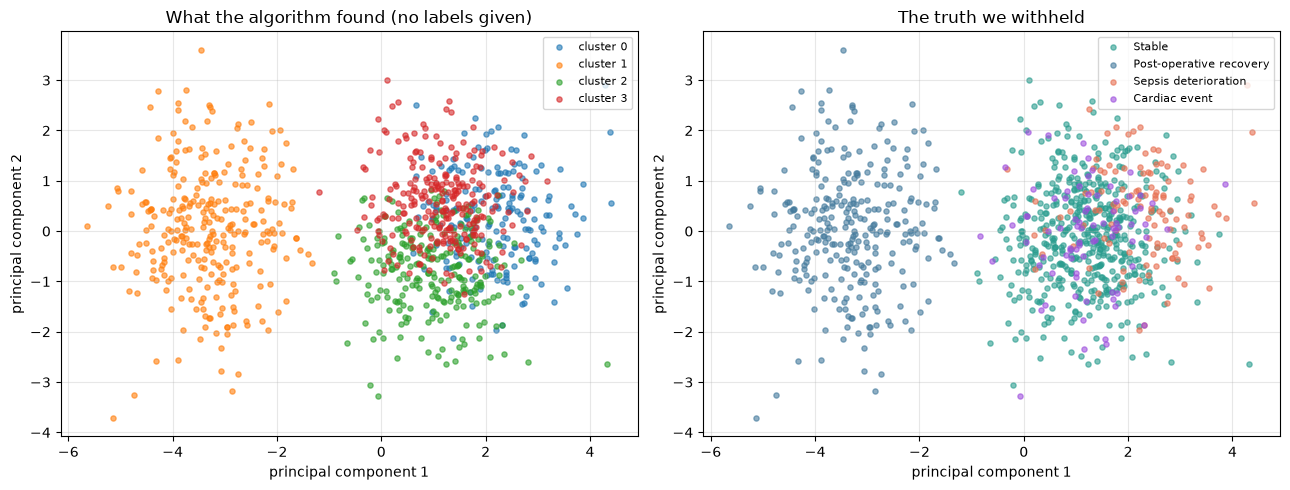

In [7]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score

# The algorithm sees X only. y is not passed, and is not available to it.
kmeans = KMeans(n_clusters=4, n_init=10, random_state=RANDOM_SEED).fit(X)
clusters = kmeans.labels_

# PCA is used only to draw 15 dimensions on a flat page.
coords = PCA(n_components=2, random_state=RANDOM_SEED).fit_transform(X)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for c in range(4):
    m = clusters == c
    axes[0].scatter(coords[m, 0], coords[m, 1], s=14, alpha=0.6, label=f"cluster {c}")
axes[0].set_title("What the algorithm found (no labels given)")
axes[0].legend(fontsize=8)

for name, colour in colours.items():
    m = archetypes == name
    axes[1].scatter(coords[m, 0], coords[m, 1], s=14, alpha=0.6,
                    color=colour, label=ARCHETYPES[name]["label"])
axes[1].set_title("The truth we withheld")
axes[1].legend(fontsize=8)

for ax in axes:
    ax.set_xlabel("principal component 1")
    ax.set_ylabel("principal component 2")

fig.tight_layout()
plt.show()

In [8]:
print("cluster membership vs the withheld archetype:")
print(pd.crosstab(patients["archetype"], clusters).to_string())
print()

summary = (
    pd.DataFrame({"cluster": clusters, "deteriorated": y})
    .groupby("cluster")["deteriorated"]
    .agg(patients="size", deterioration_rate="mean")
    .round(3)
)
print(summary.to_string())
print()
print(f"agreement with the true archetypes (ARI): {adjusted_rand_score(archetypes, clusters):.3f}")

cluster membership vs the withheld archetype:
col_0                  0    1    2    3
archetype                              
cardiac_event         20    0   29   32
post_op_recovery       0  285    0    0
sepsis_deterioration  85    0    8   21
stable                83    0  217  196

         patients  deterioration_rate
cluster                              
0             188               0.559
1             285               0.000
2             254               0.146
3             249               0.213

agreement with the true archetypes (ARI): 0.460


### Reading this honestly

The result is partial, and that is the realistic outcome.

One archetype separates cleanly: post-operative patients occupy their own region, because
starting perturbed and settling is a distinctive early-window shape. The remaining three
overlap. The clusters are **not** a rediscovery of the diagnosis.

But look at the deterioration rate per cluster. Without ever seeing an outcome, the
algorithm has produced groups whose deterioration rates differ substantially — one cluster
carries several times the risk of another. It found a high-risk group by noticing that
those patients' early vitals look alike, not by being told what risk is.

An ARI around 0.4 is the honest summary: real structure, imperfectly aligned with the
clinical categories we happen to care about.

**The trap to avoid.** Clusters are not diagnoses. The algorithm optimized for compactness
in a 15-dimensional space that we constructed by choosing those 15 features. Change the
features and the clusters change. A cluster becomes clinically meaningful only when someone
with domain knowledge examines it and decides it is — and that person is doing the
interpretation, not the algorithm.

---

# Question 3 — Semi-supervised learning

> *"Chart review is expensive. We funded 20 reviews. The other 956 patients are still
> sitting in the warehouse, unlabelled. Can they help?"*

This is the most realistic constraint in clinical machine learning, and the least discussed.
Raw data is abundant and nearly free — every monitor, every lab, every note. **Labels are
scarce and expensive**, because a label means a qualified person read a chart and adjudicated
an outcome.

Semi-supervised learning tries to use the unlabelled majority to improve a model trained on
the labelled handful. The idea is appealing enough that it is often assumed to work.

It does not always work. This section shows both outcomes, because knowing the difference is
the actual skill.

## First: a case where it works beautifully

Forget patients for a moment. Here is a synthetic two-dimensional dataset in the shape of two
interleaved crescents. We label exactly **one point per class** — two labels for 400 points —
and compare two approaches.

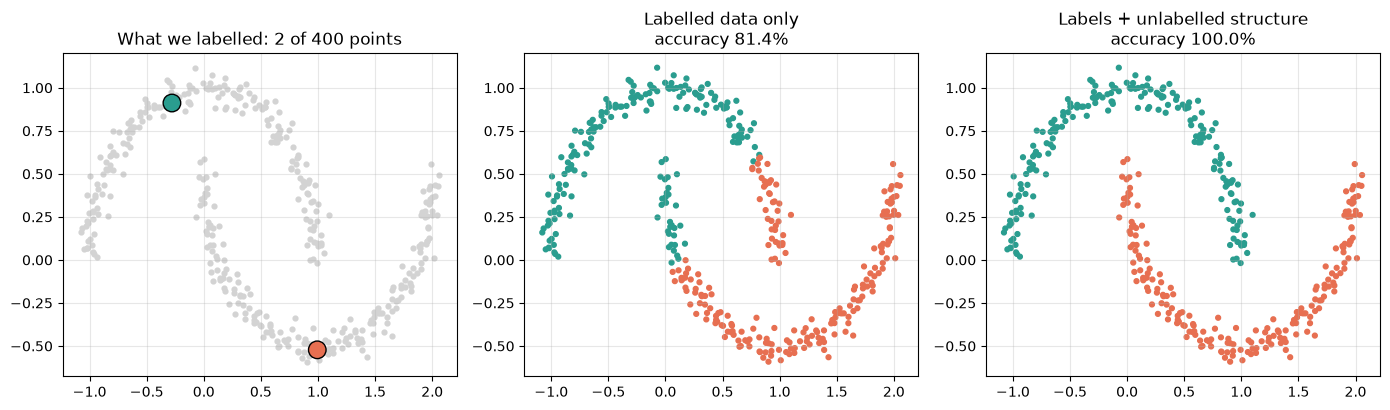

labelled data only        : 81.4%
labels + unlabelled data  : 100.0%


In [9]:
from sklearn.datasets import make_moons
from sklearn.semi_supervised import LabelPropagation
from sklearn.metrics import accuracy_score

X_moons, y_moons = make_moons(n_samples=400, noise=0.05, random_state=0)

rng = np.random.default_rng(3)
idx = np.arange(len(X_moons))
labelled = np.concatenate([
    rng.choice(idx[y_moons == 0], 1, replace=False),
    rng.choice(idx[y_moons == 1], 1, replace=False),
])
unlabelled = np.setdiff1d(idx, labelled)

# (a) supervised, using only the 2 labelled points
supervised_only = LogisticRegression().fit(X_moons[labelled], y_moons[labelled])
acc_supervised = accuracy_score(y_moons[unlabelled], supervised_only.predict(X_moons[unlabelled]))

# (b) semi-supervised, using the 2 labels AND the 398 unlabelled points
y_partial = np.full(len(X_moons), -1)       # -1 marks "unlabelled"
y_partial[labelled] = y_moons[labelled]
propagated = LabelPropagation(kernel="knn", n_neighbors=7, max_iter=2000).fit(X_moons, y_partial)
acc_semi = accuracy_score(y_moons[unlabelled], propagated.transduction_[unlabelled])

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
axes[0].scatter(X_moons[:, 0], X_moons[:, 1], s=12, c="lightgrey")
axes[0].scatter(X_moons[labelled, 0], X_moons[labelled, 1],
                s=160, c=["#2a9d8f", "#e76f51"], edgecolor="black", zorder=3)
axes[0].set_title("What we labelled: 2 of 400 points")

axes[1].scatter(X_moons[:, 0], X_moons[:, 1], s=12,
                c=[["#2a9d8f", "#e76f51"][p] for p in supervised_only.predict(X_moons)])
axes[1].set_title(f"Labelled data only\naccuracy {acc_supervised:.1%}")

axes[2].scatter(X_moons[:, 0], X_moons[:, 1], s=12,
                c=[["#2a9d8f", "#e76f51"][p] for p in propagated.transduction_])
axes[2].set_title(f"Labels + unlabelled structure\naccuracy {acc_semi:.1%}")

fig.tight_layout()
plt.show()

print(f"labelled data only        : {acc_supervised:.1%}")
print(f"labels + unlabelled data  : {acc_semi:.1%}")

Near-perfect recovery of both crescents from two labelled points. The unlabelled data did
the work.

**Why it worked.** The method assumes that points close together share a label, and it
propagates labels along the dense regions of the data. In this dataset that assumption is
exactly true: each crescent is a connected ridge of points with a clear gap between them.
Label one point anywhere on a crescent and the label flows along it.

This assumption has a name — the **cluster assumption** — and the entire benefit depends
on it holding.

## Now: the same method on our patients

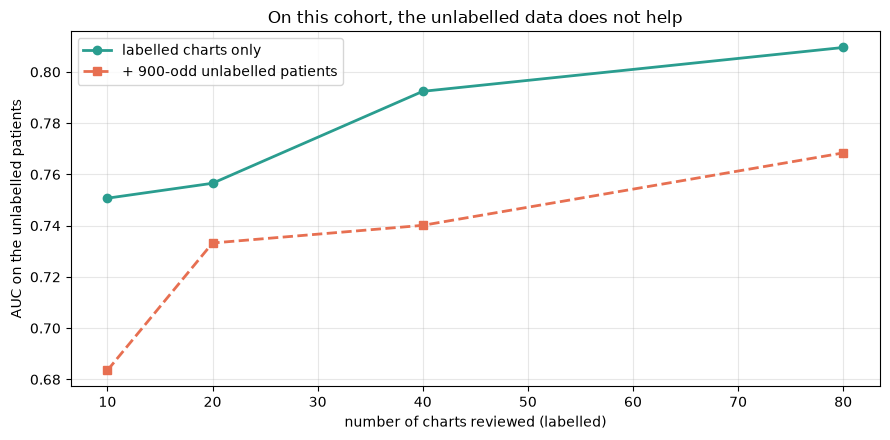

 labelled charts  labels only (AUC)  labels + unlabelled (AUC)  change
              10              0.751                      0.684  -0.067
              20              0.757                      0.733  -0.023
              40              0.792                      0.740  -0.052
              80              0.810                      0.768  -0.041


In [10]:
label_budgets = [10, 20, 40, 80]
rows = []

for n_labels in label_budgets:
    sup_scores, semi_scores = [], []
    for seed in range(20):
        r = np.random.default_rng(seed)
        all_idx = np.arange(len(X))
        lab = np.concatenate([
            r.choice(all_idx[y == 0], n_labels // 2, replace=False),
            r.choice(all_idx[y == 1], n_labels // 2, replace=False),
        ])
        unlab = np.setdiff1d(all_idx, lab)

        sup = LogisticRegression(max_iter=1000).fit(X[lab], y[lab])
        sup_scores.append(roc_auc_score(y[unlab], sup.predict_proba(X[unlab])[:, 1]))

        partial = np.full(len(X), -1)
        partial[lab] = y[lab]
        prop = LabelPropagation(kernel="knn", n_neighbors=7, max_iter=2000).fit(X, partial)
        semi_scores.append(roc_auc_score(y[unlab], prop.label_distributions_[unlab][:, 1]))

    rows.append({
        "labelled charts": n_labels,
        "labels only (AUC)": np.mean(sup_scores),
        "labels + unlabelled (AUC)": np.mean(semi_scores),
    })

comparison = pd.DataFrame(rows)
comparison["change"] = comparison["labels + unlabelled (AUC)"] - comparison["labels only (AUC)"]

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(comparison["labelled charts"], comparison["labels only (AUC)"],
        "o-", color="#2a9d8f", lw=2, label="labelled charts only")
ax.plot(comparison["labelled charts"], comparison["labels + unlabelled (AUC)"],
        "s--", color="#e76f51", lw=2, label="+ 900-odd unlabelled patients")
ax.set_xlabel("number of charts reviewed (labelled)")
ax.set_ylabel("AUC on the unlabelled patients")
ax.set_title("On this cohort, the unlabelled data does not help")
ax.legend()
fig.tight_layout()
plt.show()

print(comparison.round(3).to_string(index=False))

### The unlabelled data made it worse, consistently, at every budget

This is not a tuning failure. It is the same algorithm, in the same configuration, that
reached ~100% on the crescents a moment ago. What changed is the data.

**Why it failed.** Look back at the PCA plot in Section 2. The deteriorating patients do not
occupy their own ridge with a gap around it — in the first six hours they sit *inside* the
same cloud as everyone else. That is precisely why the supervised model in Section 1 managed
AUC in the mid-0.8s rather than 0.99: the groups genuinely overlap this early.

The cluster assumption is false here. Label propagation flows labels across a boundary that
does not follow any gap in the data, so it spreads them into the wrong neighbourhoods and
degrades the estimate. More data, used on a false assumption, is worse than less data used
carefully.

### The lesson to carry out of this section

When a vendor or a research team tells you *"we have millions of unlabelled records, so we
can do more with fewer labels"* — that claim is conditional, not automatic. It holds when the
structure in the unlabelled data lines up with the clinical distinction you care about. It
fails when it does not, and nothing about having more records tells you which case you are in.

The question to ask is: **do the patients you care about actually look different from the
rest, in the features you have, at the time you need to decide?** If the honest answer is
"only slightly", more unlabelled data will not rescue the model.

That is a question about physiology and data collection, not about algorithms.

---

# Question 4 — Self-supervised learning

> *"Never mind who deteriorated. What does a normal stay look like — and who does not look
> like that?"*

The first three questions all pointed at an outcome, even when we hid it. This one does not.
We take only the patients we are confident were uneventful, and train a model whose entire
job is to **reproduce its own input**.

That sounds pointless. It is not. We force the data through a narrow bottleneck — 15 numbers
compressed to 4, then expanded back to 15. To get through the bottleneck the network has to
discover what normal stays have in common and throw away everything else. It builds a
compressed theory of normality.

Then we show it every patient, including ones it never saw, and measure how badly it fails to
reconstruct each. Patients who reconstruct poorly are **unlike the normal patients**. This
architecture is called an **autoencoder**, and the technique is anomaly detection.

The supervision comes from the data itself — the input is also the target — which is why this
is called self-supervised. No chart review is required at all.

> **A note on the window.** The three sections above used the first six hours, because they
> asked predictive questions and we wanted the difficulty to be honest. This section asks a
> descriptive one — *who had an unusual stay?* — so here we summarize the **whole 24 hours**.
> It is the same 976 patients throughout. What changes with the question is not only the
> method, but which slice of the record the question entitles you to look at.

In [11]:
def summarise_full_stay(stay: pd.DataFrame) -> pd.Series:
    """Same 15 summaries, computed over the complete stay rather than the first 6 hours."""
    hours = stay["minutes_since_admission"].to_numpy() / 60.0
    features = {}
    for channel in CHANNELS:
        values = stay[channel].to_numpy()
        features[f"{channel}_mean"] = values.mean()
        features[f"{channel}_sd"] = values.std()
        features[f"{channel}_slope"] = np.polyfit(hours, values, 1)[0]
    return pd.Series(features)


full_stay = raw.groupby("patient_id").apply(summarise_full_stay, include_groups=False)
full_stay = full_stay.loc[patients.index]          # exactly the same 976 patients

X_full_raw = full_stay[FEATURES].to_numpy(float)
print(f"same patients, wider window: {X_full_raw.shape}")

same patients, wider window: (976, 15)


trained on 207 stable patients only
the model has never seen a deteriorating patient
final reconstruction loss on stable patients: 0.4126


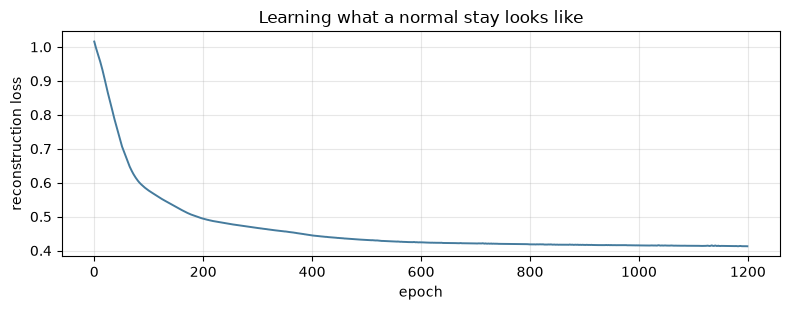

In [12]:
# Split the stable patients: some to learn normality from, some held back to set a threshold
# and to check the false-alarm rate on patients the model never saw.
stable_idx = np.where(archetypes == "stable")[0]
everyone_else = np.where(archetypes != "stable")[0]

stable_train, stable_heldout = train_test_split(stable_idx, test_size=0.40, random_state=RANDOM_SEED)
stable_fit, stable_val = train_test_split(stable_train, test_size=0.30, random_state=RANDOM_SEED)

# Scale using stable patients only -- "normal" is all we are allowed to know.
scaler = StandardScaler().fit(X_full_raw[stable_fit])
X_full = scaler.transform(X_full_raw)

torch.manual_seed(RANDOM_SEED)
n_features = X_full.shape[1]

autoencoder = nn.Sequential(
    nn.Linear(n_features, 16), nn.ReLU(),
    nn.Linear(16, 4), nn.ReLU(),        # the bottleneck: 15 numbers -> 4
    nn.Linear(4, 16), nn.ReLU(),
    nn.Linear(16, n_features),
)

optimizer = torch.optim.Adam(autoencoder.parameters(), lr=5e-3)
loss_fn = nn.MSELoss()
train_tensor = torch.tensor(X_full[stable_fit], dtype=torch.float32)

history = []
for epoch in range(1200):
    optimizer.zero_grad()
    loss = loss_fn(autoencoder(train_tensor), train_tensor)
    loss.backward()
    optimizer.step()
    history.append(loss.item())

print(f"trained on {len(stable_fit)} stable patients only")
print(f"the model has never seen a deteriorating patient")
print(f"final reconstruction loss on stable patients: {history[-1]:.4f}")

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(history, color="#457b9d", lw=1.4)
ax.set_xlabel("epoch"); ax.set_ylabel("reconstruction loss")
ax.set_title("Learning what a normal stay looks like")
fig.tight_layout()
plt.show()

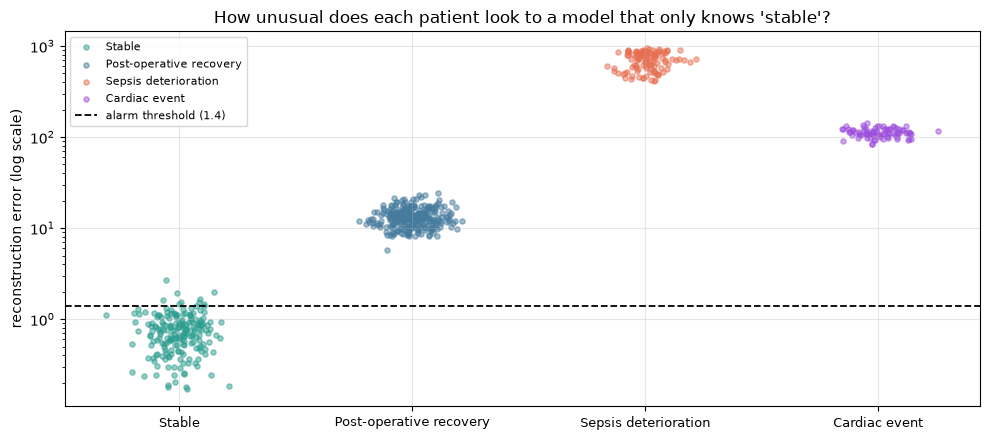

                      patients  median_error  flagged_rate
archetype                                                 
cardiac_event               81    112.199997          1.00
post_op_recovery           285     12.880000          1.00
sepsis_deterioration       114    717.710022          1.00
stable                     199      0.740000          0.05


In [13]:
with torch.no_grad():
    all_tensor = torch.tensor(X_full, dtype=torch.float32)
    reconstruction_error = ((autoencoder(all_tensor) - all_tensor) ** 2).mean(dim=1).numpy()

# Threshold: the 95th percentile of stable patients the model did NOT train on.
threshold = np.quantile(reconstruction_error[stable_val], 0.95)

evaluation_idx = np.concatenate([stable_heldout, everyone_else])
results = pd.DataFrame({
    "archetype": archetypes[evaluation_idx],
    "error": reconstruction_error[evaluation_idx],
    "deteriorated": y[evaluation_idx],
})
results["flagged"] = (results["error"] > threshold).astype(int)

fig, ax = plt.subplots(figsize=(10, 4.5))
for name, colour in colours.items():
    subset = results[results["archetype"] == name]["error"]
    ax.scatter(np.random.normal(list(colours).index(name), 0.08, len(subset)), subset,
               s=14, alpha=0.5, color=colour, label=ARCHETYPES[name]["label"])
ax.axhline(threshold, color="black", ls="--", lw=1.3,
           label=f"alarm threshold ({threshold:.1f})")
ax.set_yscale("log")
ax.set_xticks(range(4))
ax.set_xticklabels([ARCHETYPES[n]["label"] for n in colours], fontsize=9)
ax.set_ylabel("reconstruction error (log scale)")
ax.set_title("How unusual does each patient look to a model that only knows 'stable'?")
ax.legend(fontsize=8, loc="upper left")
fig.tight_layout()
plt.show()

print(results.groupby("archetype").agg(
    patients=("error", "size"),
    median_error=("error", "median"),
    flagged_rate=("flagged", "mean"),
).round(2).to_string())

In [14]:
flagged = results[results["flagged"] == 1]
print(f"patients flagged as unusual      : {len(flagged)}")
print(f"of those, actually deteriorated  : {flagged['deteriorated'].mean():.0%}")
print(f"of those, were post-operative    : {(flagged['archetype'] == 'post_op_recovery').mean():.0%}")
print()
print(f"false-alarm rate on stable patients the model never saw: "
      f"{results[results['archetype'] == 'stable']['flagged'].mean():.0%}")

patients flagged as unusual      : 489
of those, actually deteriorated  : 40%
of those, were post-operative    : 58%

false-alarm rate on stable patients the model never saw: 5%


### It worked. That is the problem.

The detector is, on its own terms, close to flawless. Every sepsis and every cardiac patient
is flagged. The false-alarm rate on unseen stable patients sits near the 5% the threshold was
set for. And it achieved this **having never been shown a single deteriorating patient**. We
never defined sepsis. We never labelled anything.

Now read the second number. Of everyone it flagged, only around 40% actually deteriorated.

The rest are post-operative patients — flagged at essentially 100%, and entirely as intended,
because a post-operative recovery *is* unusual compared with a stable stay. Their vitals are
genuinely perturbed. The model is not malfunctioning. It answered the question it was asked
with considerable skill.

**The question it was asked was "is this unusual?" — not "is this patient in danger?"**

Those two questions come apart constantly in healthcare, and conflating them is how an
anomaly detector becomes an alarm-fatigue generator. Expected, explicable abnormality is
everywhere on a ward: post-op, dialysis, palliative care, pediatrics, pregnancy, anyone on
rate-control medication. All unusual. Most entirely fine.

Closing that gap requires exactly the thing this method was attractive for avoiding: somebody
has to label outcomes, so the model can learn which deviations matter. That is Question 1
again, and it is why self-supervised methods are usually a first stage rather than a finished
system.

---

## And the fifth: reinforcement learning

Most taxonomies list a fifth family, and this notebook does not demonstrate it. The reason is
worth more than a demonstration would be.

The four questions above all learn from a **dataset** — a fixed record of what already
happened. Reinforcement learning does not. It learns from **consequences**: it takes an
action, observes what follows, receives a reward signal, and adjusts. It needs an environment
to act in, not a table to read.

That is why it cannot be bolted onto our cohort. There is no action to take in a completed
set of monitor traces, and no consequence to observe. The question would have to become
*"what should we do next, and what happened because we did it?"* — a different kind of
question entirely, which is Session 4's subject.

It is also why you see reinforcement learning in games, robotics and logistics, and very
rarely in deployed clinical systems. Those domains let you run millions of consequence-free
trials. Healthcare does not. A reinforcement learner improves by trying things and being
wrong, and the thing it would be trying things on is a patient.

There is a deeper obstacle. Reinforcement learning requires someone to write down a reward
function — a single number the system maximizes. For a ward, what would you write? Survival
to discharge rewards discharging the sickest patients elsewhere. Minimizing length of stay
rewards premature discharge. Minimizing cost rewards undertreatment. Each is defensible in
isolation and dangerous when optimized against relentlessly by something with no clinical
judgement and no stake in the outcome.

The honest summary for Session 1: reinforcement learning is real, it is powerful, and the
hard part in healthcare is not the mathematics. It is that stating the goal precisely enough
for a machine to pursue it turns out to be a clinical and ethical problem, not a technical
one.

---

# What to take away

One ward of simulated patients. Four questions. Four families of method, and four quite
different kinds of answer.

| | The question | What it needs | What it gives you | Where it misleads |
|---|---|---|---|---|
| **Supervised** | Which patients deteriorate? | A labelled outcome for every training patient | A prediction you can calibrate and audit | Only as good as the labels; correlation, not cause |
| **Unsupervised** | Is there structure here? | Nothing but the features | Groups you had not named | Clusters are not diagnoses, and shift when features shift |
| **Semi-supervised** | Can unlabelled data stretch scarce labels? | A few labels, a lot of unlabelled data | Sometimes a real gain | Fails silently when the structure does not match the question |
| **Self-supervised** | What is normal, and who departs from it? | Only examples of normal | Anomaly detection with no labelling cost | Finds *unusual*, which is not the same as *dangerous* |

### The five points worth keeping

1. **The taxonomy is a list of questions, not a menu of algorithms.** The same patients
   supported all four. What changed was what we asked, and what we were willing to pay for in
   labelling effort.

2. **Labels are the expensive ingredient.** Not data, not compute. Everything in Section 1
   depended on someone having reviewed 976 charts. The whole of Sections 3 and 4 exists
   because that is often unaffordable.

3. **More data is not automatically better.** Section 3 made a model worse by adding 950
   patients, because the assumption that justified adding them was false for this cohort.

4. **A model answers the question you asked, not the one you meant.** Section 4's detector was
   excellent at finding unusual patients and useless at finding endangered ones, and nothing
   in its performance metrics would have told you.

5. **The hard questions are clinical, not technical.** Which outcome to label, which features
   to compute, whether unusual means dangerous, what a reward function should contain. None of
   these are settled by choosing a better algorithm.

### Honest limitations of this notebook

- **The patients are simulated**, from four tidy archetypes. Real wards do not sort themselves
  into four clean groups, and real monitor data is full of artefact, missingness, disconnected
  leads and documentation gaps that are absent here. Expect every result below to be optimistic.
- **The features were handed to the methods**, already chosen and already computed. That choice
  did more work than any algorithm here, and in a real project it is where the clinical
  expertise goes.
- **Results are illustrative, not benchmarks.** The AUC in Section 1 reflects how this
  simulator was written. It is not evidence about early-warning scores in general.
- **None of this is a clinical tool.** It is a teaching example, built to make a distinction
  legible. It has not been validated, and must not inform the care of a real patient.

### Where to go next in this course

- `s1_01_intro_explicit_vs_learning.ipynb` — programming versus learning, in more depth
- `s1_05_linear_regression.ipynb` and `s1_02_gradient_descent_visual.ipynb` — how the fitting in
  Section 1 actually happens
- `s2_15_overfitting_vs_underfitting.ipynb` — why a model that fits perfectly may be worthless
- `s2_12_unsupervised_learning_phenotypes.ipynb` — Section 2, taken much further
- `s2_18_precision_recall_clinical.ipynb` — the trade-off behind Section 4's false alarms